# Z–hadron correlations by event mixing: CMS's procedure, step by step

CMS ([2507.09307](https://arxiv.org/abs/2507.09307)) measures the charged-particle yield
correlated with a Z boson, per Z, as a difference of two pair distributions in
**Δφ = φ_ch − φ_Z** and **Δη = η_ch − y_Z** (the track's pseudorapidity against the Z's
rapidity; CMS's Δy_ch,Z, the axis `dy` in the code):

* **S, the signal**: every Z paired with the tracks of *its own* event;
* **B, the mixed background**: every Z paired with the tracks of *other* Z events, 10 per Z;
* **Δ⟨N_ch⟩ = S − B**: the pairs the Z's own event has beyond an uncorrelated one. B carries
  everything that does not know the Z (the underlying event, in Pb+Pb the whole fluid) and the
  detector's acceptance, so both cancel; what is left is the recoiling jet, its quenching and the
  medium's response (the wake).

CMS publishes two projections of S − B: **Δφ** (all Δη) and **Δη on the Z side**
(|Δφ| < π/2), each merged over ± and per unit angle. This notebook builds them from the pools of
a Z+jet production, with [`hist`](https://hist.readthedocs.io) histograms, in the order of the
analysis:

1. what an event contributes;
2. **S** in 2D (Δη × Δφ);
3. **B**, CMS's way: 10 partner events per Z;
4. **S − B** in 2D;
5. the **projections** CMS publishes, and how they come out of the 2D maps;
6. the **errors**, and why they come from replicates, not from the histograms;
7. every event a partner (`all`) and the model's exact answer (`factorized`): the same mean,
   different noise;
8. the corrected projections, method by method.

It reproduces `mix.py`'s modes `cms10`, `all` and `factorized` (checked below). The
definitions in one notation: [`MIXING_MODES.md`](MIXING_MODES.md); the workflow:
[`ANA_Zhadron.md`](ANA_Zhadron.md).

**Data**: the Pb+Pb pools of `runs/<run>/data/mix/pbpb` (`python mix.py --run <run>
--pools-only` builds them). The default run, `zjet_test`, has 4 hydro backgrounds: too few
for 10 partners from 10 other backgrounds, so its partners are fewer and its numbers
meaningless. On a campaign: `ZJET_RUN=zjet_c00-01 jupyter lab zhadron_mixing.ipynb` (11k Z's:
~1 min, ~3 GB), or several campaigns' pools at once with `ZJET_PBPB_POOLS="<dir> <dir>"`.
The outputs stored with the notebook are those of Pb+Pb 0–30 % campaigns c00 + c01
(`ZJET_RUN=zjet_c00-01`: 11,226 Z's on 800 hydro backgrounds).

In [1]:
import glob
import os
import sys

import matplotlib.pyplot as plt
import mplhep
from matplotlib.colors import Normalize
import numpy as np

sys.path.insert(0, os.path.abspath(".."))                       # jetcorr
try:
    import jetscape  # noqa: F401
except ImportError:              # PyJetscape not installed in this kernel: this checkout's
    sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "..", "python")))
import zjet_mixing as zm
from cms2507 import rebin_y
from jetcorr import runs

RUN = os.environ.get("ZJET_RUN", "zjet_test")
PBPB = os.environ.get("ZJET_PBPB_POOLS", runs.data(RUN, "mix", "pbpb")).split()
SEED = int(os.environ.get("ZJET_SEED", "1"))          # mix.py's --seed
Z_SHOWN = os.environ.get("ZJET_Z")                    # the Z shown on its own (default below)
N_MIX = 10                                            # partners per Z (CMS: 10)


def pool_files(dirs):
    # mix.py's .npz or zhadron_pools' *_pool.root, of one or several campaigns
    out = []
    for d in dirs:
        out += (sorted(glob.glob(os.path.join(d, "*_pool.root")))
                or sorted(glob.glob(os.path.join(d, "*.npz"))))
    if not out:
        raise FileNotFoundError(f"no pools in {dirs}: python mix.py --run {RUN} --pools-only")
    return out


pb = zm.Pool.load(pool_files(PBPB))
pb.rotate_backgrounds([SEED, 0x726F74])               # as mix.py: the event planes at random
blocks = pb.blocks(100)                               # the jackknife's blocks of backgrounds
print(f"Pb+Pb: {pb.n} selected Z's on {pb.n_bg} hydro backgrounds (effective {zm.n_eff(pb.w):.0f} "
      f"after the weights)")
if pb.n_bg <= N_MIX:
    print(f"only {pb.n_bg} backgrounds: 10 partners from 10 other backgrounds need a campaign "
          "(ZJET_RUN=zjet_c00-01); fewer partners below")

Pb+Pb: 11226 selected Z's on 800 hydro backgrounds (effective 8134 after the weights)


In [2]:
PT_SHORT = ["1–2 GeV", "2–4 GeV", "4–10 GeV"]                 # the track p_T classes
DETA_LABEL, DPHI_LABEL = r"$\Delta\eta = \eta_{ch} - y_Z$", r"$\Delta\phi = \phi_{ch} - \phi_Z$"


def pi_ticks(axis):
    axis.set_ticks(np.pi / 2 * np.arange(-1, 4))
    axis.set_ticklabels([r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$"])


def maps(panels, title, zlabel="pairs per Z per bin"):
    # 2D maps (Δη × Δφ), one per (hist, panel title, diverging colours) of ``panels``
    fig, ax = plt.subplots(1, len(panels), figsize=(5.4 * len(panels), 4.4), squeeze=False)
    for a, (h2, label, diverging) in zip(ax[0], panels):
        kw = {"cmap": "viridis"}
        if diverging:                                             # symmetric about 0
            lim = float(np.nanpercentile(np.abs(h2.values()), 99)) or 1.0
            kw = {"cmap": "RdBu_r", "norm": Normalize(-lim, lim)}   # beyond: the end colours
        art = mplhep.hist2dplot(h2, ax=a, flow=None, **kw)
        art.cbar.set_label(zlabel)
        a.set_xlabel(DETA_LABEL)
        a.set_ylabel(DPHI_LABEL)
        pi_ticks(a.yaxis)
        a.set_title(label)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def per_pt(h, title, diverging=False, **kw):
    maps([(h[{"pt": c}], PT_SHORT[c], diverging) for c in range(zm.N_PT)], title, **kw)


def rebin(x, k):
    # Δη: |Δη| < 4 in bins of 0.4 k (CMS's Pb+Pb binning: k = 2), the mean of the bins merged
    return rebin_y(x, np.zeros_like(x), k)[0]

## 1. What an event contributes

A pool (`mix.py`'s map step, one per production file) holds per selected Z event *i* (CMS's Z
selection, `zjet_wake.CMS_2507`):

* its Z (y_i, φ_i) and its **weight** w_i = σ_window / N_window × N_coll. The production has
  the same number of events in every p̂T window and draws the geometry minimum-bias-like; in
  nature the cross section falls over the windows and Z's come ∝ N_coll. With w the model's
  events stand for the physical Z population, the one CMS records unweighted;
* **S_i**: the tracks of its own event (charged, |η| < 2.4, the Z's leptons out) in its Z frame,
  histogrammed in (p_T class, Δη in 0.4, Δφ in π/10). Twice: averaged over the event's **40
  oversamples** (`S_full`: the mean hadronized event, the hadronization noise averaged away), and
  for **one oversample** k1 (`S_one`: "the recorded collision", one sample as in data);
* the tracks of that one oversample: what the event gives **as a partner** to other Z's.

`Pool.to_hist` gives any of these as a `hist.Hist` with named axes `pt`, `dy` (Δη), `dphi`:
`per="event"` an event's own map, `per="background"` the mean per Z of each hydro background,
by default the weighted mean over all Z's. One Z, one collision:

Z 10483: y_Z = -0.11, phi_Z = +0.30 (rotated), weight 1.17, hydro background 747; tracks in its Z frame per p_T class: [1456, 191, 9]


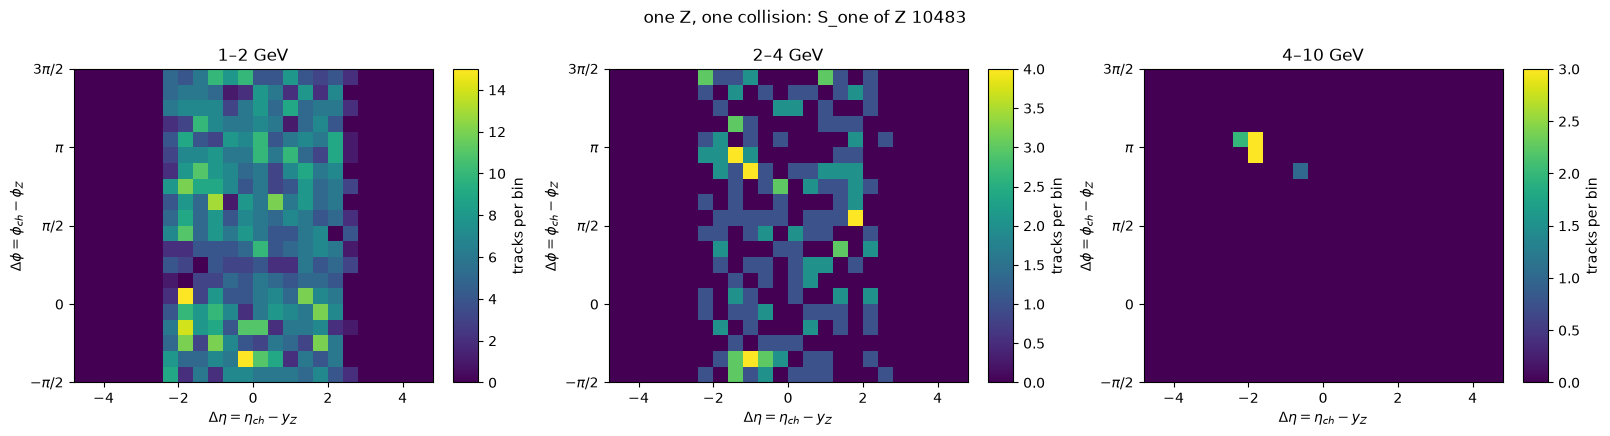

In [3]:
# by default a Z near y = 0 whose recorded collision shows its recoil (4-10 GeV, |Δφ - π| < π/4)
cphi = 0.5 * (zm.DPHI[1:] + zm.DPHI[:-1])
recoil = pb.S_one[:, 2][:, :, np.abs(cphi - np.pi) < np.pi / 4].sum(axis=(1, 2))
I0 = int(Z_SHOWN) if Z_SHOWN else int(np.argmax(np.where(np.abs(pb.y) < 0.5, recoil, -1)))
one = pb.to_hist("S_one", per="event", events=[I0])[{"event": 0}]
print(f"Z {I0}: y_Z = {pb.y[I0]:+.2f}, phi_Z = {pb.phi[I0]:+.2f} (rotated), weight {pb.w[I0]:.2f}, "
      f"hydro background {pb.bg[I0]}; tracks in its Z frame per p_T class: "
      f"{one[{'dy': sum, 'dphi': sum}].values().astype(int).tolist()}")
per_pt(one, f"one Z, one collision: S_one of Z {I0}", zlabel="tracks per bin")

At 1–2 GeV the map is the fluid: about a thousand tracks over the acceptance, which is
|η_ch| < 2.4 seen from the Z: Δη = −2.4 − y_Z … 2.4 − y_Z. At 4–10 GeV the few tracks are
the recoiling jet's, at Δφ ≈ π (this Z was picked for that; `ZJET_Z=<index>` shows another).

## 2. The signal S

S is the mean over the Z's of their same-event maps, each Z weighted:
**S = Σ_i w_i S_i / Σ_i w_i**, here with S_i the 40-oversample mean (`S_full`), as `mix.py`'s
`cms10` mode. In Δη it is the acceptance seen from the Z's rapidities: tracks spread over
|η| < 2.4 folded with the Z's y distribution, a triangle-like shape over |Δη| < 4.8. In Δφ it
is nearly flat at low p_T, where the Z-correlated part is a few per cent of the bulk; at
4–10 GeV the recoiling jet stands out at Δφ ≈ π already in S.

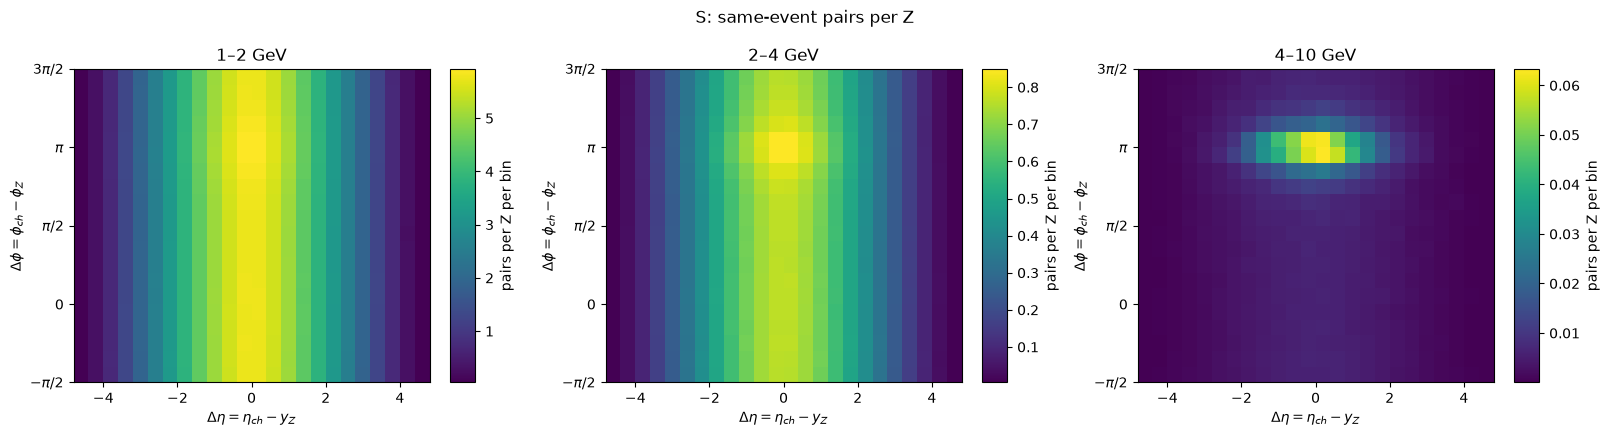

pairs per Z, per p_T class: [1387.   183.5    2.6]


In [4]:
S = pb.S_full.astype(float)                      # (Z, p_T class, Δη, Δφ): per Z, own event
W = pb.w.sum()
S_mean = np.tensordot(pb.w, S, axes=1) / W
hS = pb.to_hist("S_full")                        # the same mean, from the pool's sums
assert np.allclose(hS.values(), S_mean, rtol=1e-5)
per_pt(hS, "S: same-event pairs per Z")
print("pairs per Z, per p_T class:", np.round(hS[{"dy": sum, "dphi": sum}].values(), 1))

## 3. The mixed background B, CMS's way

For every Z, CMS takes **10 other Z events** and pairs the Z with their tracks: they come from
the same detector and the same population of collisions, but know nothing of this Z. Here, as
in `mix.py`'s `cms10` mode (`zm.explicit_partners`, the same seed):

* the 10 partners come from **10 different hydro backgrounds, never the Z's own**: the Z events
  of one fluid share its multiplicity and flow pattern (and the oversamples' random numbers), and
  a partner on the same fluid would cancel part of S's fluctuations, which mixing in data never
  can;
* they are **drawn ∝ w**: a background with probability ∝ the summed weight of its Z events,
  then an event inside it ∝ w. CMS's B is an equal average over partners from the physical
  population, and this reproduces it;
* each partner contributes **one recorded collision** (its `S_one` oversample's tracks), moved
  into this Z's frame, Δη = η_j − y_i, Δφ = φ_j − φ_i:

  **B_i = (1/10) Σ_{j ∈ partners(i)} H_i[tracks_j]**.

`explicit_partners` draws the partners and returns the per-Z observables; the 2D maps B_i are
rebuilt here from its draws, track by track.

Z 10483 (background 747): partners [5415, 7208, 9326, 8136, 3576, 1822, 4159, 66, 11004, 2382] from backgrounds [388, 516, 666, 582, 259, 132, 300, 4, 784, 172], weights [1.03, 1.57, 0.98, 1.35, 1.92, 1.26, 1.07, 0.74, 3.83, 2.16]


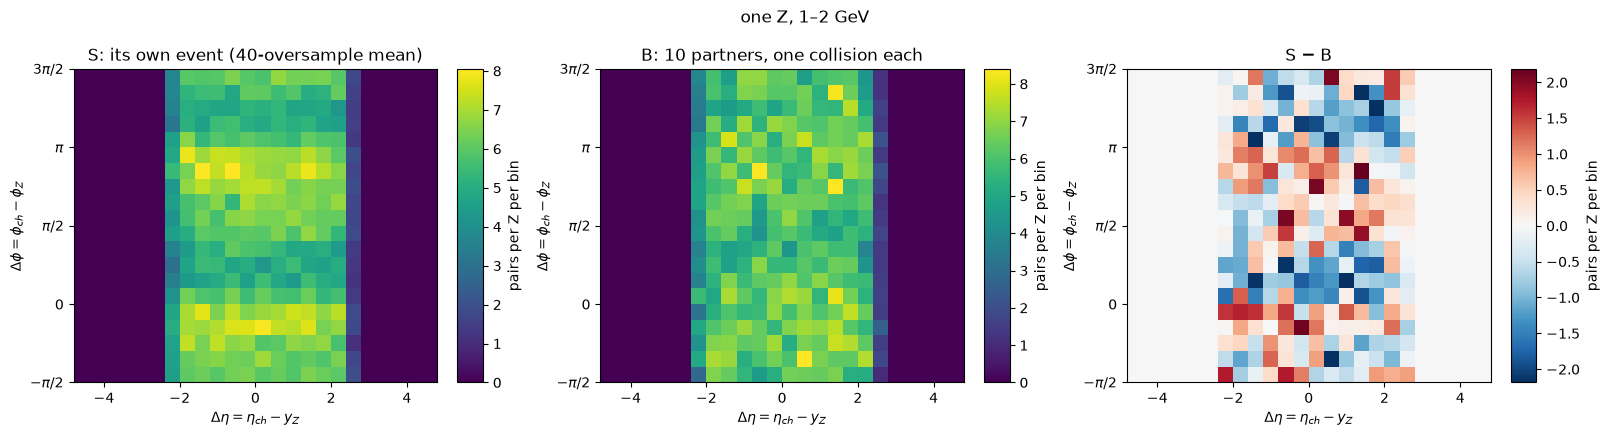

In [5]:
res = zm.explicit_partners(pb, np.arange(pb.n), np.arange(pb.n), pb.w, n_mix=N_MIX, s="full",
                           seed=SEED)
B = np.zeros_like(S)                             # per Z: its partners' tracks in its frame
for i, js in enumerate(res["partners"]):
    trk = [pb.tracks(j) for j in js]             # (p_T class, eta, phi) of each partner
    ipt, eta, phi = (np.concatenate([t[k] for t in trk]) for k in range(3))
    B[i] = zm.z_hist(ipt, eta, phi, pb.y[i], pb.phi[i]) / len(js)
D = S - B                                        # S - B per Z
dphi_z, dy_z = zm.observables(D)
assert np.allclose(dphi_z, res["dphi"]) and np.allclose(dy_z, res["dy"])   # mix.py's, Z by Z
js = res["partners"][I0]
print(f"Z {I0} (background {pb.bg[I0]}): partners {js} from backgrounds {pb.bg[js].tolist()}, "
      f"weights {np.round(pb.w[js], 2).tolist()}")
c = 0                                            # 1-2 GeV
maps([(zm.zframe_hist(S[I0])[{"pt": c}], "S: its own event (40-oversample mean)", False),
      (zm.zframe_hist(B[I0])[{"pt": c}], f"B: {len(js)} partners, one collision each", False),
      (zm.zframe_hist(D[I0])[{"pt": c}], "S − B", True)],
     f"one Z, {PT_SHORT[c]}")

One Z alone: S − B is noise, the event-to-event fluctuations of a fluid (its multiplicity, its
flow) against 10 others. The correlation appears in the average over the Z's.

## 4. B averaged, and why the partners follow the weights

**B = Σ_i w_i B_i / Σ_i w_i** has S's acceptance shape and, at low p_T, its level: the
uncorrelated pairs. The levels agree only if the Z's and their partners come from the same
population. The Z's are weighted by w, and the partners are drawn ∝ w, so they do. Counting the
Z's as produced, unweighted, puts the Z's at the production's geometric centrality (more
peripheral events, fewer tracks) and the partners at the physical one. The last line below shows
the mismatch; it would appear in S − B as a spurious flat level.

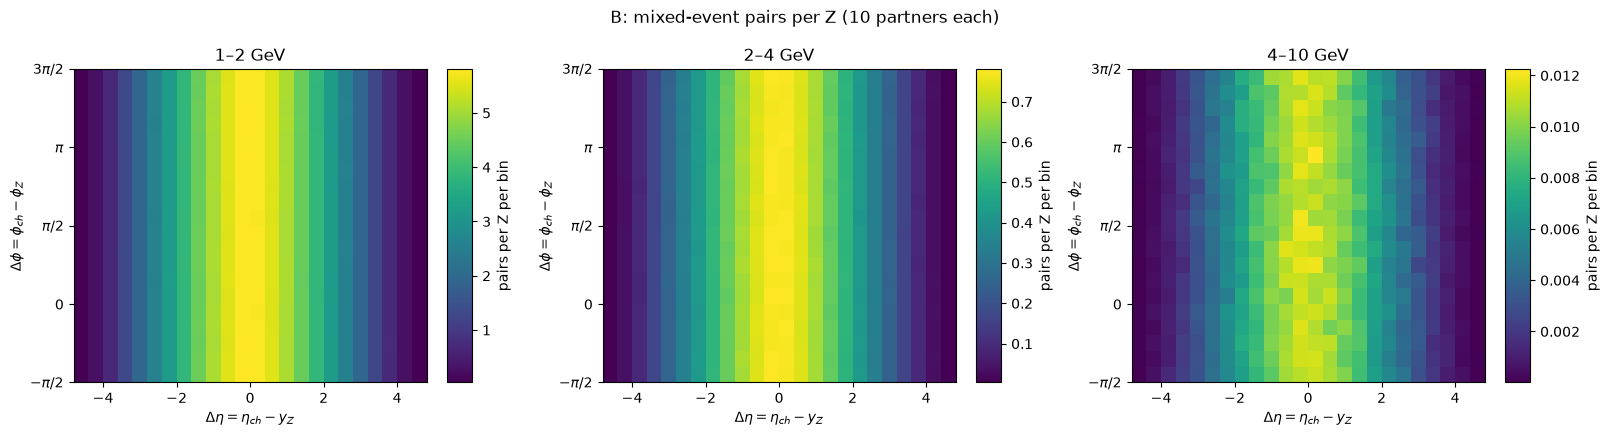

pairs per Z, per p_T class:
  S, Z's weighted     [1387.   183.5    2.6]
  B, Z's weighted     [1386.3  183.9    2.6]
  S, Z's unweighted   [1189.9  155.8    2.5]   <- not the partners' population


In [6]:
B_mean = np.tensordot(pb.w, B, axes=1) / W
hB = zm.zframe_hist(B_mean)
per_pt(hB, "B: mixed-event pairs per Z (10 partners each)")
tot = lambda x: np.round(x.sum(axis=(-2, -1)), 1)
print("pairs per Z, per p_T class:")
print(f"  S, Z's weighted     {tot(S_mean)}")
print(f"  B, Z's weighted     {tot(B_mean)}")
print(f"  S, Z's unweighted   {tot(S.mean(axis=0))}   <- not the partners' population")

## 5. S − B in 2D

**⟨S − B⟩ = Σ_i w_i (S_i − B_i) / Σ_i w_i**. Its error per bin comes from a jackknife over
blocks of hydro backgrounds (`zm.explicit_replicates`). Each block is left out of S (its Z's)
**and** of B (its events as the other Z's partners), as a smaller sample would have neither;
section 7 shows why both matter. `zm.zframe_hist` makes the map a `hist.Hist`, its variance
the jackknife's.

What is left is correlated with the Z. At Δφ ≈ π is the recoiling jet: the Z balances the
jet's parton, and |Δη| ≲ 2 because the jet's rapidity is not the Z's. B's partners are Z events
too, with their own recoil jets at random Δφ, so S − B integrates to about zero and lies below
zero away from the jet. In Pb+Pb the medium's response sits on top: extra soft particles
around the jet, and a depletion on the Z side, the diffusion wake.

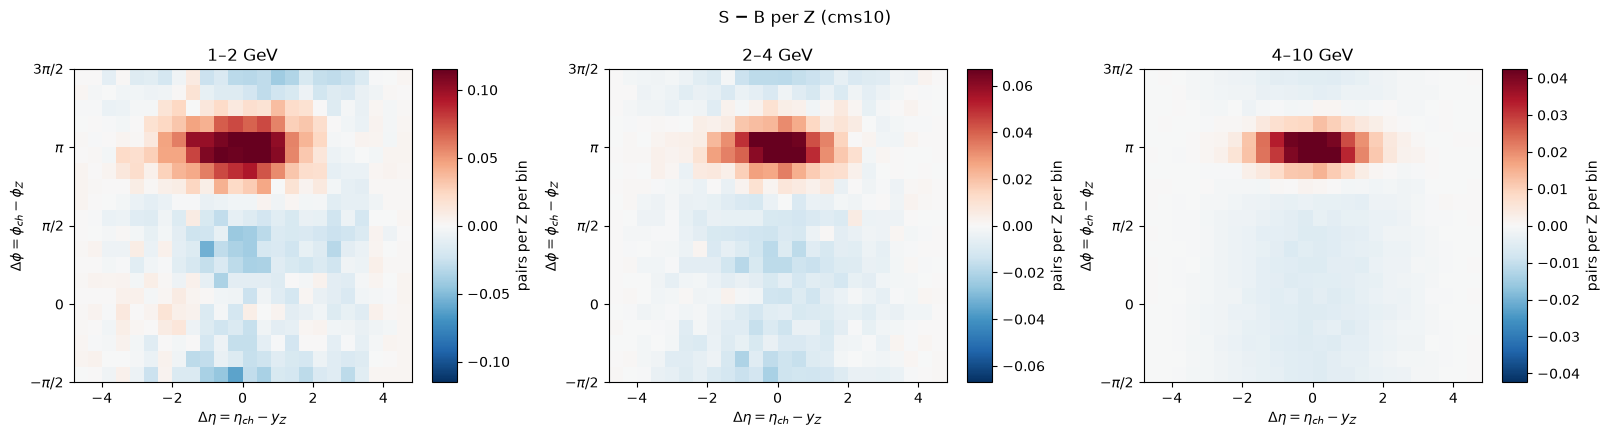

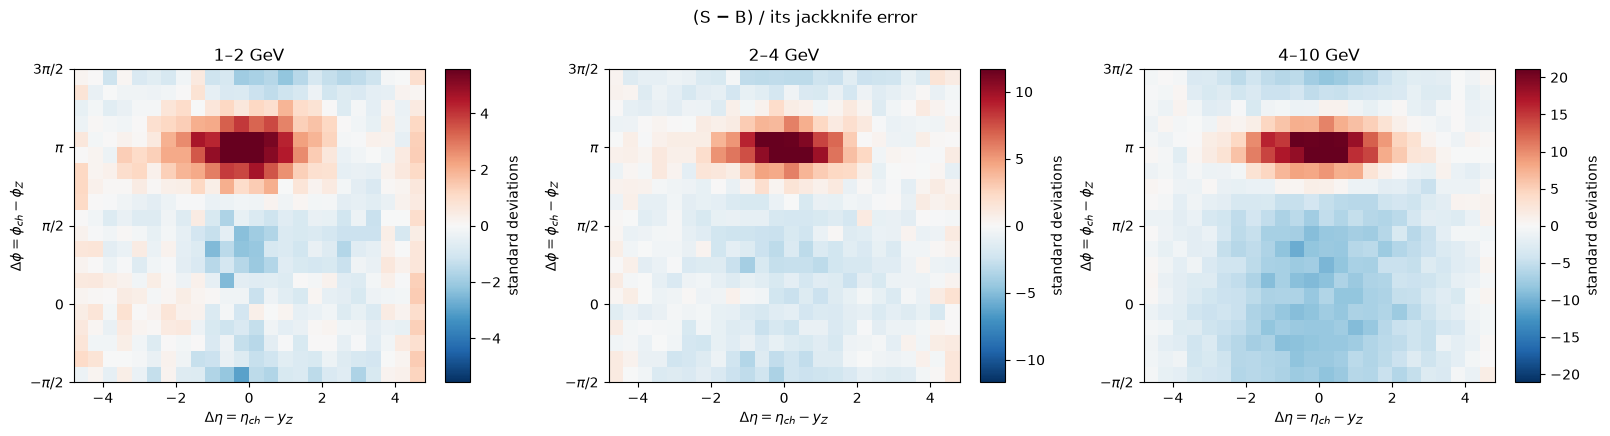

In [7]:
res["B"] = B                                     # the B maps built above, for the replicates
m2d, reps2d = zm.explicit_replicates(pb, np.arange(pb.n), pb.w, res, S, blocks)
jk2d = zm.jackknife(reps2d)
assert np.allclose(m2d, np.tensordot(pb.w, D, axes=1) / W)
hD = zm.zframe_hist(m2d, jk2d, "S − B, CMS's mixing (cms10)")
per_pt(hD, "S − B per Z (cms10)", diverging=True)
sig = np.divide(m2d, jk2d, out=np.full_like(m2d, np.nan), where=jk2d > 0)
per_pt(zm.zframe_hist(sig), "(S − B) / its jackknife error", diverging=True,
       zlabel="standard deviations")

## 6. The projections CMS publishes

From the 2D map, with `hist`'s sums by axis name:

* **Δφ**: sum over all Δη (`hD[{"dy": sum}]`), divide by the bin width (per radian);
* **Δη on the Z side**: sum over the Z side, |Δφ| < π/2, the first 10 of the 20 Δφ bins
  (`hD[{"dphi": slice(0, 10, sum)}]`), divide by the bin width (per unit Δη);
* **± merging**: +Δφ and −Δφ, +Δη and −Δη are the same physics, and CMS shows their average.
  The reflection is a reordering of bins (`zm.MIRROR`: the bin at −Δφ, within [−π/2, 3π/2)),
  done on the arrays.

`zm.observables` does the same in one step (`mix.py` uses it); the cell checks they agree.

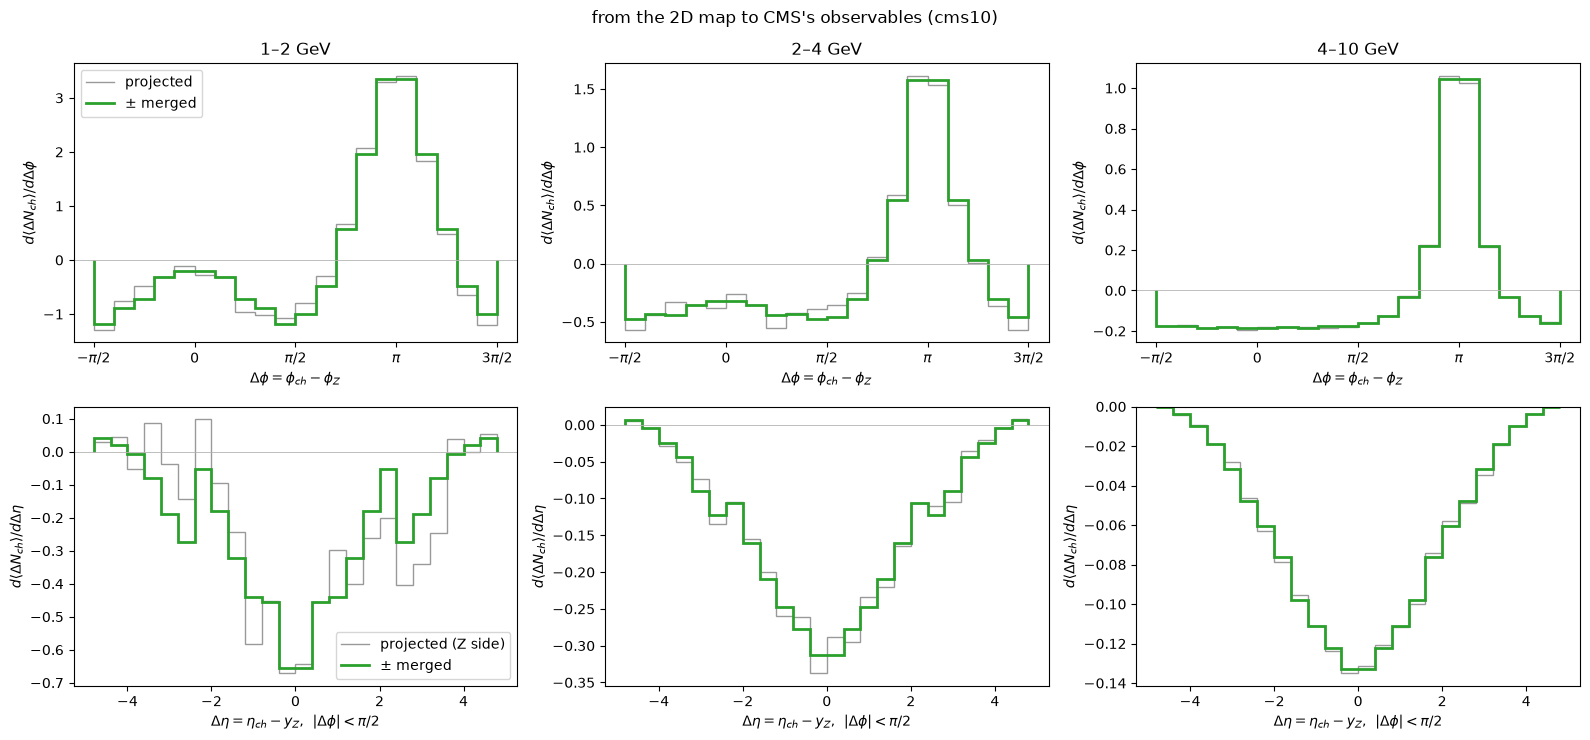

In [8]:
p = hD[{"dy": sum}]                                    # (p_T, Δφ): pairs per Z per bin
p_rad = p.values() / np.diff(zm.DPHI)                  # per radian
dphi_cms = 0.5 * (p_rad + p_rad[:, zm.MIRROR])         # +-Δφ merged
y = hD[{"dphi": slice(0, zm.N_DPHI // 2, sum)}]        # Z side, |Δφ| < π/2
y_unit = y.values() / np.diff(zm.DETA)                 # per unit Δη
dy_cms = 0.5 * (y_unit + y_unit[:, ::-1])              # +-Δη merged
ref = zm.observables(m2d)
assert np.allclose(dphi_cms, ref[0]) and np.allclose(dy_cms, ref[1])

fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for c in range(zm.N_PT):
    ax[0, c].stairs(p_rad[c], zm.DPHI, color="0.6", label="projected")
    ax[0, c].stairs(dphi_cms[c], zm.DPHI, color="C2", lw=2, label="± merged")
    ax[1, c].stairs(y_unit[c], zm.DETA, color="0.6", label="projected (Z side)")
    ax[1, c].stairs(dy_cms[c], zm.DETA, color="C2", lw=2, label="± merged")
    ax[0, c].set(title=PT_SHORT[c], xlabel=DPHI_LABEL, ylabel=r"$d\langle\Delta N_{ch}\rangle/d\Delta\phi$")
    ax[1, c].set(xlabel=DETA_LABEL + r",  $|\Delta\phi| < \pi/2$",
                 ylabel=r"$d\langle\Delta N_{ch}\rangle/d\Delta\eta$")
    pi_ticks(ax[0, c].xaxis)
    for a in ax[:, c]:
        a.axhline(0, color="0.7", lw=0.6)
ax[0, 0].legend()
ax[1, 0].legend()
fig.suptitle("from the 2D map to CMS's observables (cms10)")
fig.tight_layout()
plt.show()

## 7. The errors: from replicates, not from the histograms

Two shortcuts give wrong errors.

**Summing the bins' variances.** `hist` adds the variances of the bins it sums as if they were
independent. They are not: the tracks of one event move together (its multiplicity, its flow,
its jet), so the bins of one Z are correlated, and the ± merging adds a bin to its own mirror
image. A projection's error comes from the projections of the replicates.

**Fixing S − B per Z.** A jackknife on the per-Z values D_i = S_i − B_i leaves a block's Z's out
and keeps everything else, as if each Z's S − B were its own measurement. But the partners come
from the same sample as the Z's: a fluid with more particles than average raises the S of its
own ~14 Z's and the B of the ~140 Z's that drew its events as partners, and in the mean the two
cancel. Leaving its Z's out of S alone counts that fluctuation anyway.
`zm.explicit_replicates` leaves a block out of S and B together.

The first cell compares the three for the Δφ projection. The second tests them where the true
error is known: in disjoint sub-campaigns (10 groups of backgrounds, partners drawn inside each)
the scatter of the groups' results is the statistical error of one group, so the pull width,
scatter / quoted error, should be 1 (`mix.py`'s check 5).

In [9]:
proj = lambda X: X.sum(axis=-2) / np.diff(zm.DPHI)                 # Δφ, before the ± merge
jk_both = zm.jackknife([proj(r) for r in reps2d])                  # S and B left out together
naive = np.sqrt(p.variances()) / np.diff(zm.DPHI)                  # its bins' variances summed
_, _, jk_fixed = zm.weighted_mean(proj(D), pb.w, pb.zb, blocks)    # each Z's S - B fixed
print("error of the Δφ projection, median over the bins:")
for c in range(zm.N_PT):
    print(f"  {PT_SHORT[c]:9s} jackknife, S and B together {np.median(jk_both[c]):.3f}   "
          f"bins' variances summed {np.median(naive[c]):.3f}   jackknife, S - B fixed per Z "
          f"{np.median(jk_fixed[c]):.3f}")

error of the Δφ projection, median over the bins:
  1–2 GeV   jackknife, S and B together 0.588   bins' variances summed 0.277   jackknife, S - B fixed per Z 2.770
  2–4 GeV   jackknife, S and B together 0.123   bins' variances summed 0.066   jackknife, S - B fixed per Z 0.409
  4–10 GeV  jackknife, S and B together 0.008   bins' variances summed 0.007   jackknife, S - B fixed per Z 0.007


In [10]:
import mix                                             # noqa: E402  (the production script)

zi, Wb = zm.strict_set(pb, seed=SEED)                  # (mix.py's check also tests strict)
if len(zi) >= 2 * 10 * (N_MIX + 1):
    pulls = mix.subsample_pulls(pb, zi, Wb, 10, N_MIX, SEED, 2)
    print("pull width: scatter of 10 disjoint sub-campaigns / their quoted error, median over "
          "the bins (1: right), p_T classes 1-2, 2-4, 4-10 GeV")
    for e in ("cms10, jackknife", "cms10, jackknife S - B fixed"):
        pv = pulls[e]
        print(f"  {e:29s} " + "   ".join(f"Δ{'φ' if v == 'phi' else 'η'} "
                                          + " ".join(f"{x:4.2f}" for x in pv[v]) for v in pv))
else:
    print(f"{len(zi)} backgrounds: the sub-campaign test needs {2 * 10 * (N_MIX + 1)} (a campaign)")

pull width: scatter of 10 disjoint sub-campaigns / their quoted error, median over the bins (1: right), p_T classes 1-2, 2-4, 4-10 GeV
  cms10, jackknife              Δφ 0.80 0.90 0.89   Δη 0.57 0.65 0.86
  cms10, jackknife S - B fixed  Δφ 0.13 0.19 0.88   Δη 0.10 0.12 0.91


On a campaign (the stored outputs: c00-01) the jackknife with each Z's S − B fixed comes out 5–10
times the true error at low p_T. Leaving the block out of S and B together is right to about
20 % (a little conservative for `cms10`; the check's own precision is about ±0.2). At 4–10 GeV,
where the fluid's fluctuations matter little, both are right.

The final values: the replicates' observables, Δη in CMS's Pb+Pb bins (0.8, |Δη| < 4), as
`zm.observables_hist` histograms. They equal `mix.py`'s `cms10` rows.

In [11]:
H = {"cms10": zm.observables_hist(m2d, reps2d, k=2)}
R = mix.from_explicit(pb, res, np.arange(pb.n), pb.w, S, blocks, 2, "jk")
for var in ("phi", "y"):
    assert np.allclose(H["cms10"][var].values(), R[var][0])
    assert np.allclose(np.sqrt(H["cms10"][var].variances()), R[var][1])
print("cms10 = mix.py's cms10, values and errors")

cms10 = mix.py's cms10, values and errors


## 8. The same mean, less noise: every partner, and the model's truth

**`all`: every selected Z event a partner.** B is linear in the partners' tracks, so averaging
over *all* partners (pairs weighted w_i w_j) is one pooled lab-frame density shifted into each
Z's frame (`zm.all_partners`, `ZKernel`): the infinite-partner limit of CMS's procedure, the
same mean without partner noise. Its first map below is the noise that 10 partners add to B.

**`factorized`: the model's exact answer.** The model knows each event's Z-correlated yield:
the wake as the event's fluid minus the same fluid without the jet, oversample by oversample
(`bulk_jet − bulk_bg`), plus the jet's fragments. S − B of that content (`"zc"`) never sees the
bulk. That the mixed modes reproduce it is the closure: CMS's procedure recovers the truth.

**`strict`**, not shown here: the closest emulation of the measurement itself. The `cms10` Z's
share fluids (~14 per background) and their S is a 40-oversample mean; `strict` takes one Z per
hydro background, one oversample for S and 10 partners from that set, so that its Z's are
independent as in data and its errors are data-like. With one Z per fluid a campaign gives only
as many Z's as backgrounds, so its errors are too large for a comparison of the means; `mix.py`
runs it and quotes its errors (the spread over its Z's, and its jackknife).

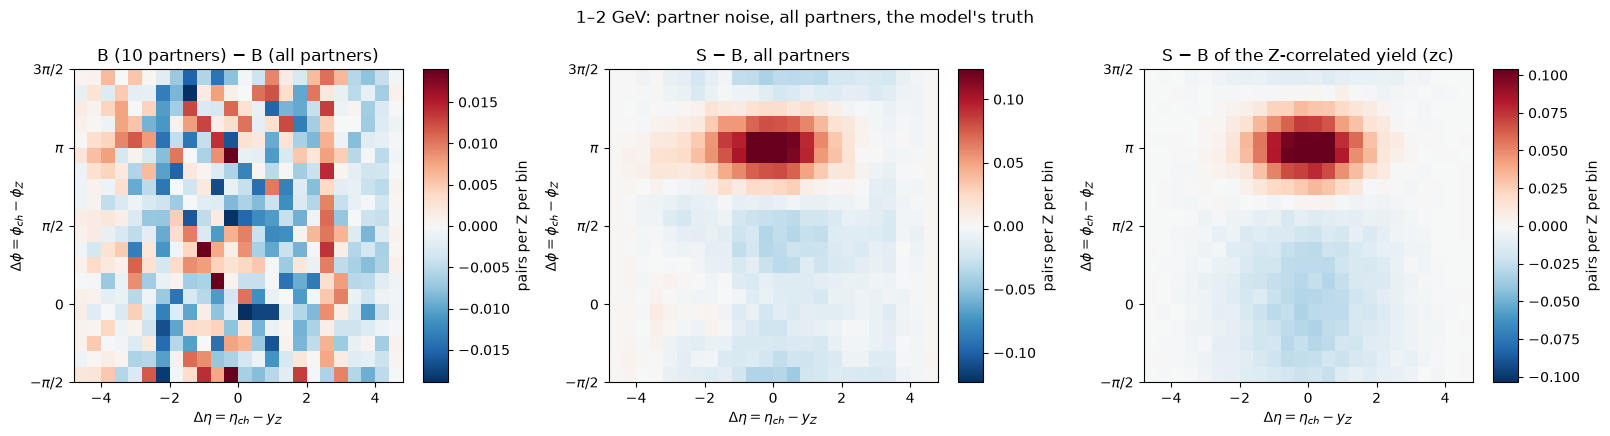

In [12]:
D_all, reps_all = zm.all_partners(pb, "full", "all", False, blocks)
H["all"] = zm.observables_hist(D_all, reps_all, k=2)
S_pool = pb.bg_SW["full"].sum(axis=0) / pb.bg_W.sum()          # = S_mean
B_pooled = S_pool - D_all
c = 0
maps([(zm.zframe_hist(B_mean - B_pooled)[{"pt": c}], "B (10 partners) − B (all partners)", True),
      (zm.zframe_hist(D_all)[{"pt": c}], "S − B, all partners", True),
      (zm.zframe_hist(zm.all_partners(pb, "zc", "all", False)[0])[{"pt": c}],
       "S − B of the Z-correlated yield (zc)", True)],
     f"{PT_SHORT[c]}: partner noise, all partners, the model's truth")

# the factorized result as mix.py: Δφ with B flat (every pair), Δη all partners but the Z's own event
Dp, rp = zm.all_partners(pb, "zc", "all", True, blocks)
Dy, ry = zm.all_partners(pb, "zc", "self", True, blocks)
H["factorized"] = {"phi": zm.observables_hist(Dp, rp)["phi"],
                   "y": zm.observables_hist(Dy, ry, k=2)["y"]}

## 9. The corrected projections, method by method

S − B in CMS's two projections, Pb+Pb 0–30 %, from the three methods: CMS's mixing with 10
partners (`cms10`), every event a partner (`all`) and the model's Z-correlated yield
(`factorized`). They differ in their errors, by how much each averages: `cms10` carries the
noise of 10 partners per Z and of the bulk, `all` only the bulk's, `factorized` neither. In the
mean they agree where the closure holds: in Δη, and in Δφ at 4–10 GeV. In Δφ at 1–4 GeV the
full-event methods (`all`, `cms10`) differ from `factorized` by a cos 2Δφ modulation, the bulk
term, which averages to zero only if a Z's direction knows nothing of its fluid's event plane.
These two campaigns show a small alignment of the Z's with their own background's event plane
(about 2.5σ), and `mix.py`'s closure check (3) finds exactly that term; more campaigns will
tell whether it is a fluctuation.

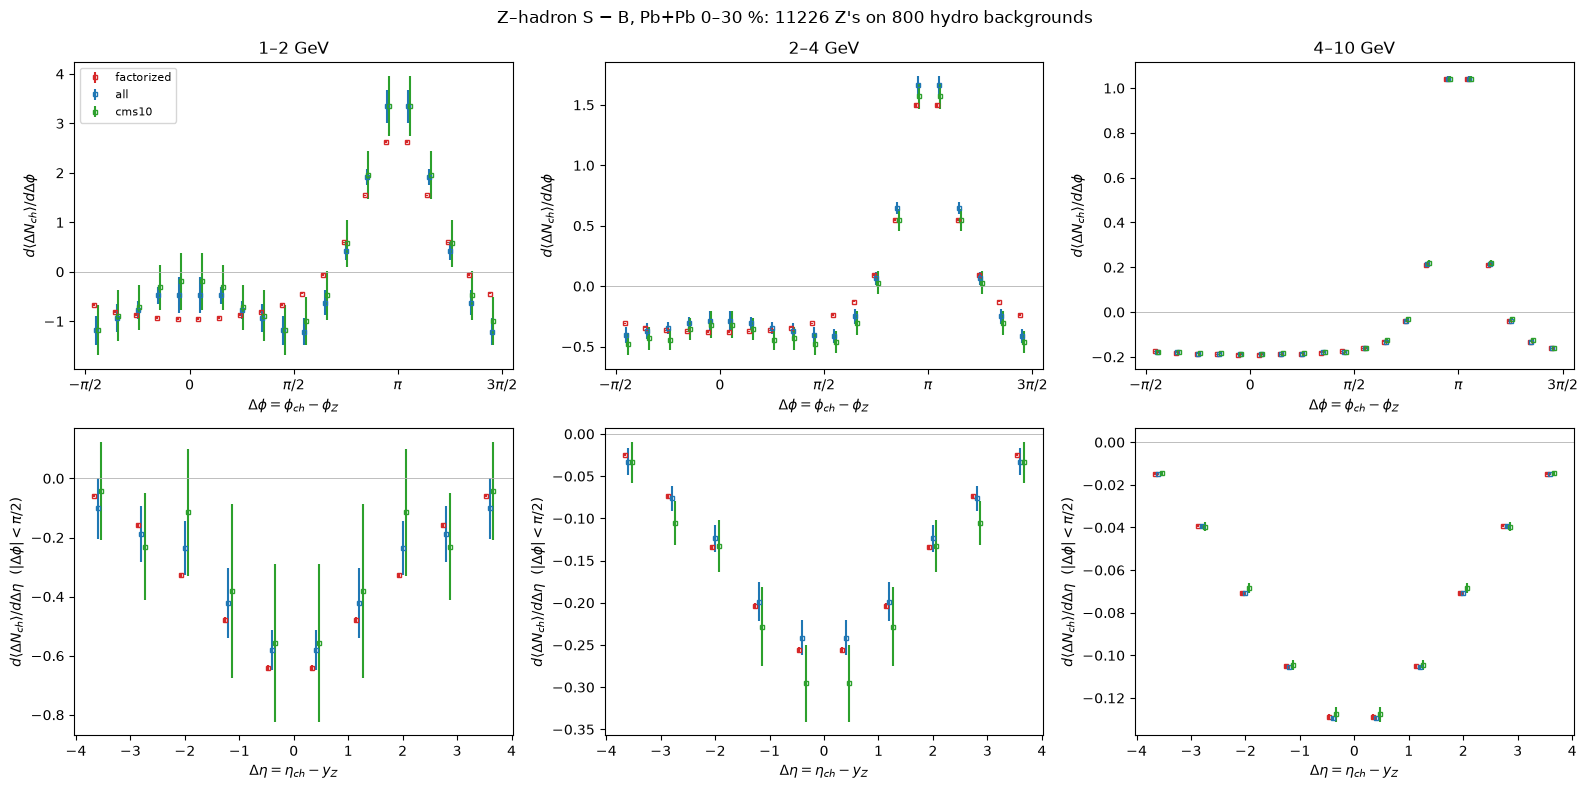

In [13]:
MODES = {"factorized": "C3", "all": "C0", "cms10": "C2"}
YLAB = {"phi": r"$d\langle\Delta N_{ch}\rangle/d\Delta\phi$",
        "y": r"$d\langle\Delta N_{ch}\rangle/d\Delta\eta$  ($|\Delta\phi| < \pi/2$)"}

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for row, var in enumerate(("phi", "y")):
    for c in range(zm.N_PT):
        width = np.diff(H["cms10"][var].axes[1].edges)[0]
        for k, (mode, colour) in enumerate(MODES.items()):
            hc = H[mode][var][{"pt": c}]
            ax[row, c].errorbar(hc.axes[0].centers + (k - 1) * 0.08 * width, hc.values(),
                                np.sqrt(hc.variances()), fmt="s", ms=3.5, mfc="none",
                                color=colour, label=mode)
        ax[row, c].axhline(0, color="0.7", lw=0.6)
        ax[row, c].set_ylabel(YLAB[var])
        ax[row, c].set_xlabel(DPHI_LABEL if var == "phi" else DETA_LABEL)
        if var == "phi":
            pi_ticks(ax[row, c].xaxis)
            ax[row, c].set_title(PT_SHORT[c])
ax[0, 0].legend(fontsize=8)
fig.suptitle(f"Z–hadron S − B, Pb+Pb 0–30 %: {pb.n} Z's on {pb.n_bg} hydro backgrounds")
fig.tight_layout()
plt.show()

The statistical errors at the first bin past 0, method by method: each step from `cms10` (10
partners per Z) to `all` (every partner) and `factorized` (no bulk at all) averages more and
leaves the mean alone.

In [14]:
for var, i0 in (("phi", 5), ("y", 5)):
    print(f"Δ{'φ' if var == 'phi' else 'η'} at {H['cms10'][var].axes[1].centers[i0]:.2f}:")
    for c in range(zm.N_PT):
        print(f"  {PT_SHORT[c]:9s} " + "  ".join(
            f"{m} {np.sqrt(H[m][var].variances()[c, i0]):.3f}" for m in MODES))

Δφ at 0.16:
  1–2 GeV   factorized 0.019  all 0.358  cms10 0.578
  2–4 GeV   factorized 0.006  all 0.085  cms10 0.112
  4–10 GeV  factorized 0.002  all 0.003  cms10 0.006
Δη at 0.40:
  1–2 GeV   factorized 0.011  all 0.068  cms10 0.267
  2–4 GeV   factorized 0.004  all 0.021  cms10 0.045
  4–10 GeV  factorized 0.001  all 0.001  cms10 0.003


## Summary: the chain

| step | what | in the code |
|---|---|---|
| S | each Z with its own event's tracks in its frame (Δη, Δφ per p_T class), weighted mean over the Z's | the pools' `S_full` / `S_one`; `Pool.to_hist("S_full")` |
| B | each Z with 10 partner Z events from 10 other hydro backgrounds, drawn ∝ w, one collision each | `zm.explicit_partners`, `zm.z_hist`; `mix.py`'s `cms10` |
| S − B | per Z, weighted mean over the Z's | `zm.explicit_replicates`, `zm.zframe_hist` |
| projections | Δφ: all Δη; Δη: the Z side; ± merged; per unit angle | `hist` sums by axis, `zm.observables` |
| errors | the replicates' projections: a jackknife over blocks of backgrounds, each left out of S and B together | `zm.explicit_replicates`, `zm.observables_hist` |
| closure | all partners (`all`) and the model's truth (`factorized`): the same mean | `zm.all_partners` |

`mix.py` runs all of this on a campaign and writes `mixing_summary.txt` with the checks
(closure, exclusion bias, the errors' test against sub-campaigns, the noise budget):
[README](README.md#event-mixing-mixpy).